In [2]:
import numpy as np
import pylab as plt
import scipy as sp
import pickle
import imageio
import os
from scipy.interpolate import interp1d

In [3]:
k=np.arange(2,16)
BohrMagneton=5.7e-5
Boltzmann=8.6e-5

In [4]:
theta=np.linspace(0,6.3,100)
XC=np.cos(theta)
SC=np.sin(theta)

In [5]:
XX,YY=np.meshgrid(np.linspace(-1,1,100),np.linspace(-1,1,100))


In [6]:
ZZ=XX+complex(0,1)*YY

2.5869999999999997

<Figure size 3200x800 with 0 Axes>

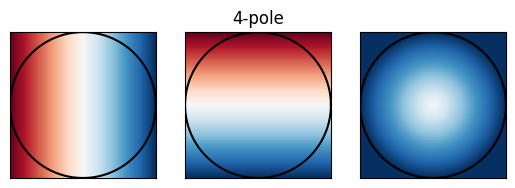

<Figure size 3200x800 with 0 Axes>

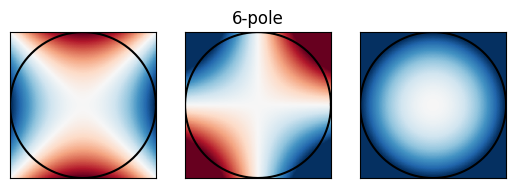

<Figure size 3200x800 with 0 Axes>

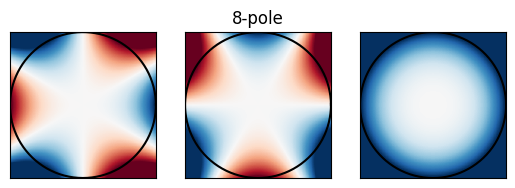

<Figure size 3200x800 with 0 Axes>

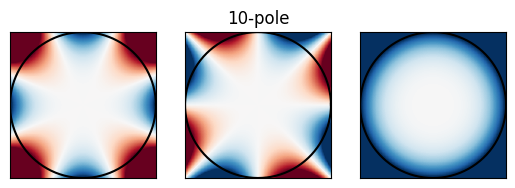

<Figure size 3200x800 with 0 Axes>

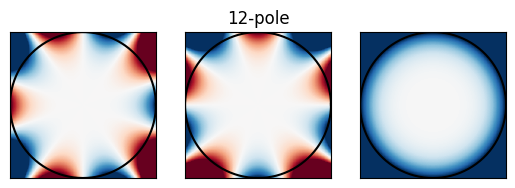

<Figure size 3200x800 with 0 Axes>

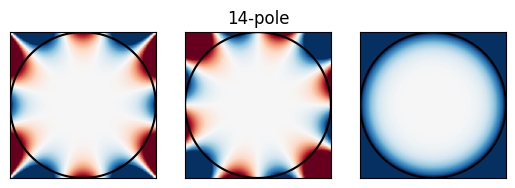

<Figure size 3200x800 with 0 Axes>

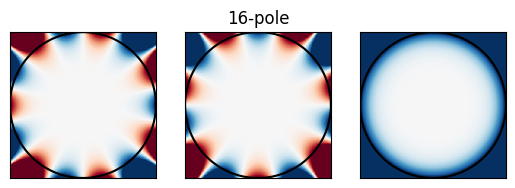

In [7]:
for k in range(2,9):
    plt.figure(figsize=(16,4),dpi=200)
    
    factor=k**2/(k**2-1)*np.sin((k+1)/(2*k)*3.14)/3.142
    #    factor=1
    Field=factor*ZZ**(k-1)
    fig, (ax1, ax2,ax3) = plt.subplots(1, 3)
    ax1.imshow(Field.real,cmap='RdBu',extent=(-1,+1,-1,1),vmin=-0.3,vmax=0.3)
    ax1.plot(XC,SC,'-',color='black')

    ax2.imshow(Field.imag,cmap='RdBu',extent=(-1,+1,-1,1),vmin=-0.3,vmax=0.3)
    ax2.plot(XC,SC,'-',color='black')

    ax3.imshow(np.abs(Field),cmap='RdBu',extent=(-1,+1,-1,1),vmin=-0.3,vmax=0.3)
    ax3.plot(XC,SC,'-',color='black')
 
    pole=(k*2)
    ax2.set_title(str(pole) + "-pole")
    ax1.set_xticks([])
    ax1.set_yticks([])
    ax2.set_xticks([])
    ax2.set_yticks([])
    ax3.set_xticks([])
    ax3.set_yticks([])
    
    

In [8]:
Ns=np.linspace(4,12,100)
def alpha(N):
    return np.sin((1/2+1/N)*np.pi)/(2*np.pi*(1/4-1/N**2))
def etaT( N,MaxB,T):
    return alpha(N)*BohrMagneton/(Boltzmann*T)

(0.0, 1.0)

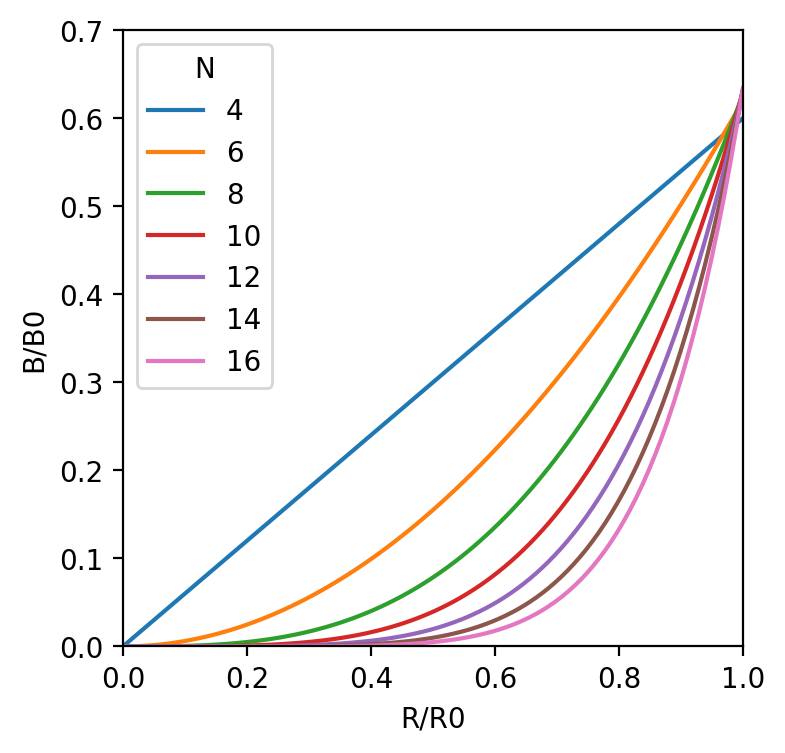

In [9]:
plt.figure(figsize=(4,4),dpi=200)
vars=np.linspace(0,1,100)
for N in [4,6,8,10,12,14,16]:
    plt.plot(vars,alpha(N)*vars**(N/2-1),label=N)
plt.legend(loc='upper left',title='N')
plt.xlabel("R/R0")
plt.ylabel("B/B0")
plt.ylim(0,0.7)
plt.xlim(0,1)

In [10]:
from scipy.special import gamma

Text(0, 0.5, '$\\alpha(N)$')

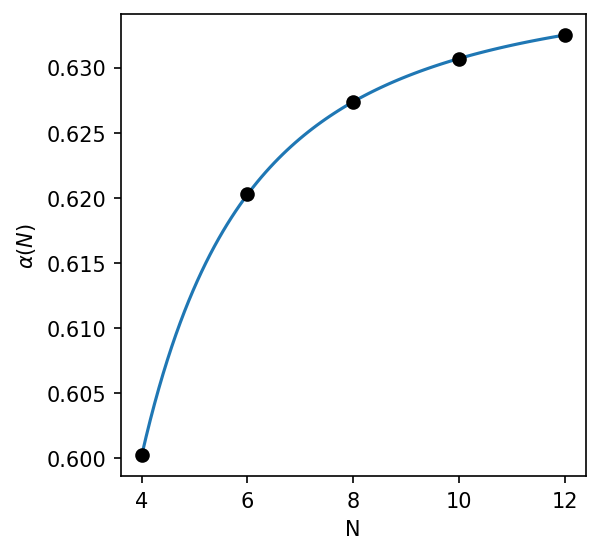

In [11]:
plt.figure(figsize=(4,4),dpi=150)
Ns=np.linspace(4,12,100)
plt.plot(Ns,alpha(Ns))
for N in [4,6,8,10,12]:
    plt.plot(N,alpha(N),'o',color='black')
plt.xlabel("N")
plt.ylabel(r"$\alpha(N)$")

In [12]:
eta=20
R0=0.01
rho0=1e18
j0=1e13
v0=37
sigma=4.4e-14


In [13]:
def equilR(eta,N,j,sigma,v):
    return 2/(np.pi*gamma((N+2)/(N-2)))*eta**(2/(N-2))*j*sigma/v



[]

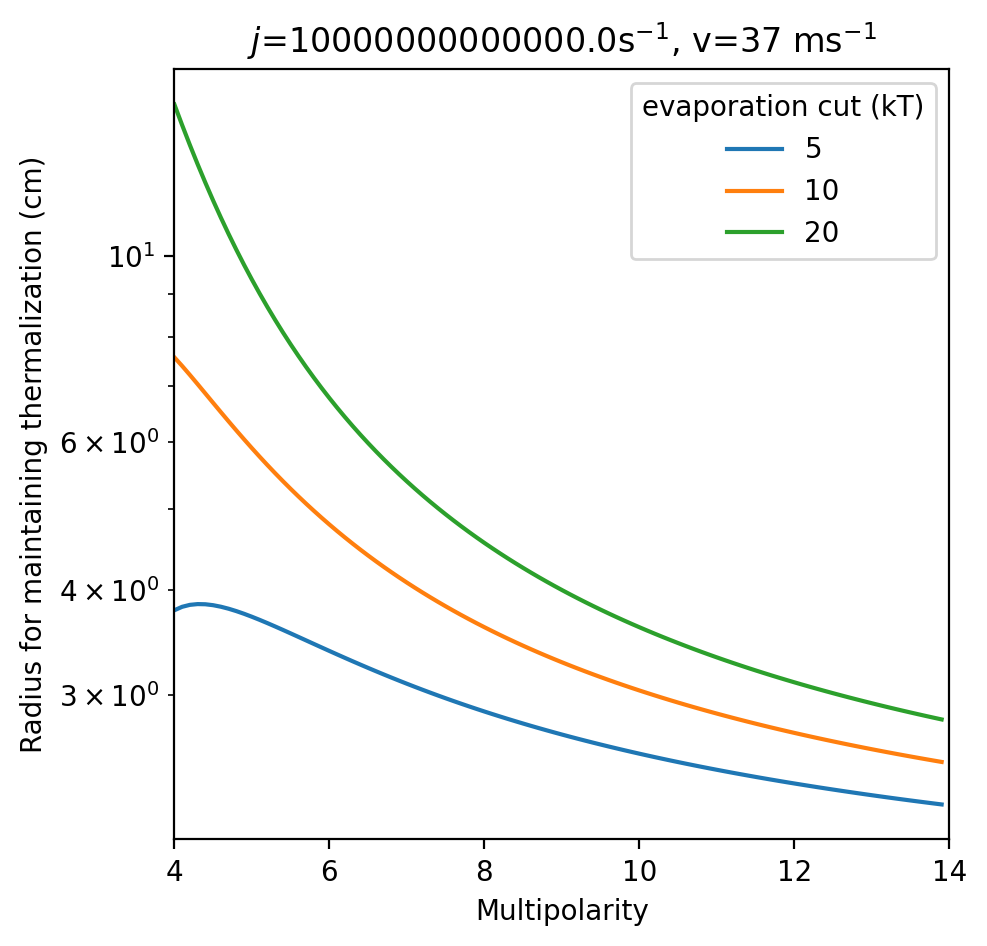

In [14]:
plt.figure(figsize=(5,5),dpi=200)
ns=np.arange(4, 14,0.1)
for etaev in [5,10,20]:
    Rs=[]
    for n in ns:
        Rs.append(equilR(etaev,n,j0,sigma,v0))
    Rs=np.array(Rs)
    plt.plot(ns,Rs*100*2,label=etaev)
    pole=((n-1)*2)

plt.legend(loc='upper right',title='evaporation cut (kT)')
plt.xlabel("Multipolarity")
plt.ylabel("Radius for maintaining thermalization (cm)")
plt.title(r"$j$="+str(j0)+"s$^{-1}$, v="+str(v0)+ " ms$^{-1}$")
plt.xlim(4,14)
#plt.ylim(0,10)
plt.semilogy()

In [15]:
def Potential(rp,eta,N):
    return eta*rp**(N/2-1)

In [16]:
def DensityFixedR(rp,eta,N,j,v,R):
    return j*eta**(4/(N-2))/(np.pi*v*sp.special.gamma((N+2)/(N-2))*R**2)*np.exp(-eta*rp**(N/2-1))

<>:24: SyntaxWarning: invalid escape sequence '\e'
<>:24: SyntaxWarning: invalid escape sequence '\e'
/var/folders/x8/m88g9m690wb3gf4t7ds85nzw0000gn/T/ipykernel_22009/2820901989.py:24: SyntaxWarning: invalid escape sequence '\e'
  plt.title("$\eta$="+str(eta)+", $j$="+str(j0)+" s$^{-1}$, $v$="+str(v0)+" ms$^{-1}$")


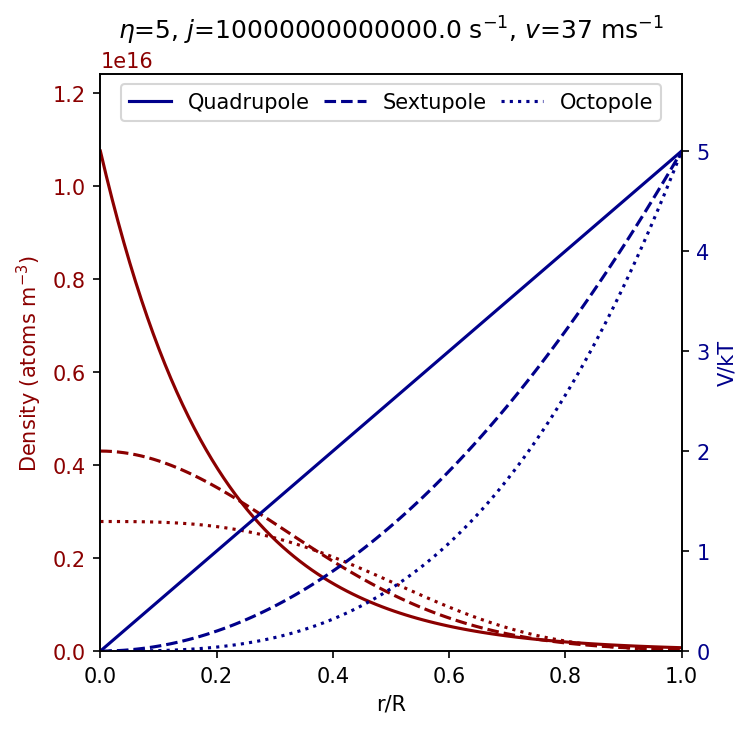

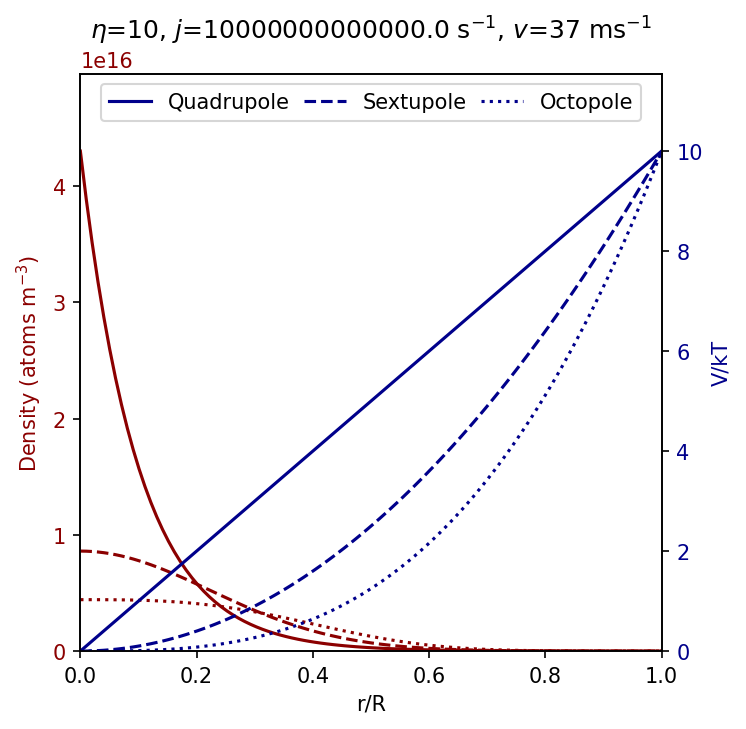

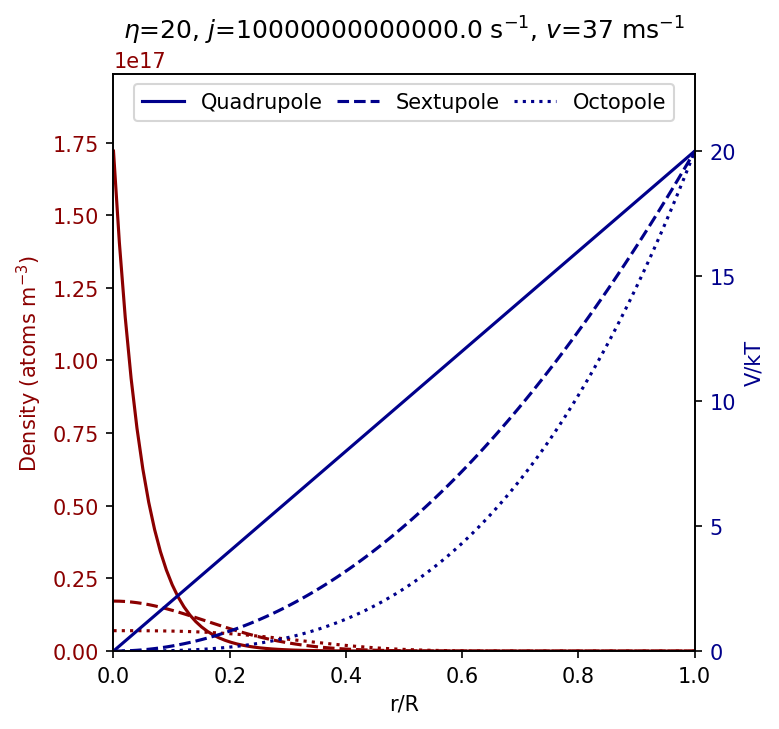

In [17]:
for eta in (5,10,20):

    rps=np.linspace(0,1,100)
    fig, ax1 = plt.subplots(figsize=(5,5),dpi=150) 
    Ns=[4,6,8]
    LineTypes=['-','--',':']
    Names=['Quadrupole','Sextupole','Octopole']
    ax1.set_xlabel('r/R')
    ax2 = ax1.twinx() 
    ax2.tick_params(axis ='y', labelcolor = 'DarkBlue') 
    ax2.set_ylabel('V/kT',color='DarkBlue') 


    ax1.tick_params(axis ='y', labelcolor = 'DarkRed') 
    ax1.set_ylabel('Density (atoms m$^{-3}$)',color='DarkRed') 

    for Ni in range(0,len(Ns)):
        ax2.plot(rps,Potential(rps,eta,Ns[Ni]),color='DarkBlue',label=Names[Ni],linestyle=LineTypes[Ni]) 
        ax1.plot(rps,DensityFixedR(rps,eta,Ns[Ni],j0,v0,R0),color='DarkRed',linestyle=LineTypes[Ni]) 
    ax1.set_ylim(0,ax1.get_ylim()[1]*1.1)
    ax2.set_ylim(0,ax2.get_ylim()[1]*1.1)
    ax1.set_xlim(0,1)
    ax2.legend(loc='upper center',ncol=3,columnspacing=0.7)
    plt.title("$\eta$="+str(eta)+", $j$="+str(j0)+" s$^{-1}$, $v$="+str(v0)+" ms$^{-1}$")

    plt.show()

<>:25: SyntaxWarning: invalid escape sequence '\e'
<>:25: SyntaxWarning: invalid escape sequence '\,'
<>:25: SyntaxWarning: invalid escape sequence '\m'
<>:25: SyntaxWarning: invalid escape sequence '\e'
<>:25: SyntaxWarning: invalid escape sequence '\,'
<>:25: SyntaxWarning: invalid escape sequence '\m'
/var/folders/x8/m88g9m690wb3gf4t7ds85nzw0000gn/T/ipykernel_22009/865574591.py:25: SyntaxWarning: invalid escape sequence '\e'
  plt.title("$\eta$="+str(eta)+", $j=10^{13}\, \mathrm{s}^{-1}$, $v$="+str(v0)+" $\mathrm{m\,s}^{-1}$")
/var/folders/x8/m88g9m690wb3gf4t7ds85nzw0000gn/T/ipykernel_22009/865574591.py:25: SyntaxWarning: invalid escape sequence '\,'
  plt.title("$\eta$="+str(eta)+", $j=10^{13}\, \mathrm{s}^{-1}$, $v$="+str(v0)+" $\mathrm{m\,s}^{-1}$")
/var/folders/x8/m88g9m690wb3gf4t7ds85nzw0000gn/T/ipykernel_22009/865574591.py:25: SyntaxWarning: invalid escape sequence '\m'
  plt.title("$\eta$="+str(eta)+", $j=10^{13}\, \mathrm{s}^{-1}$, $v$="+str(v0)+" $\mathrm{m\,s}^{-1}$")


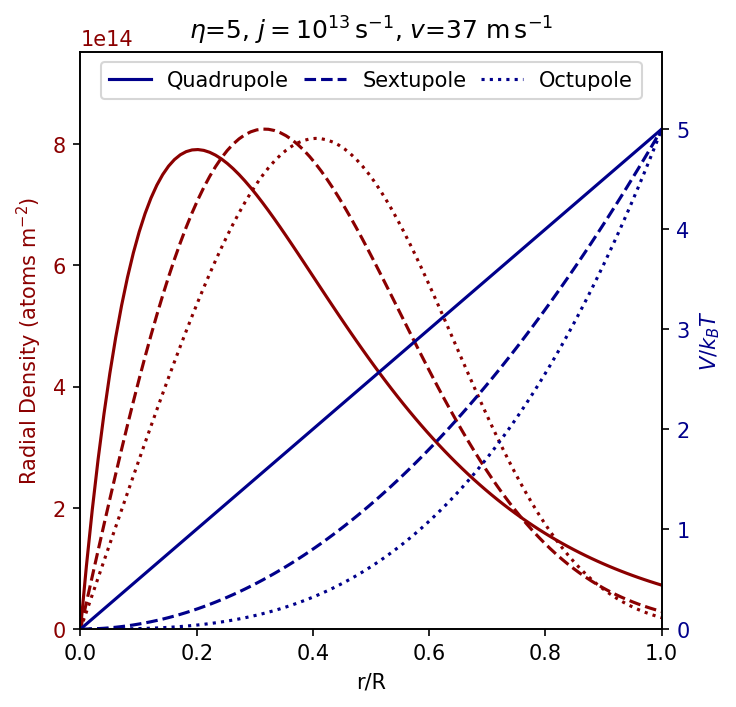

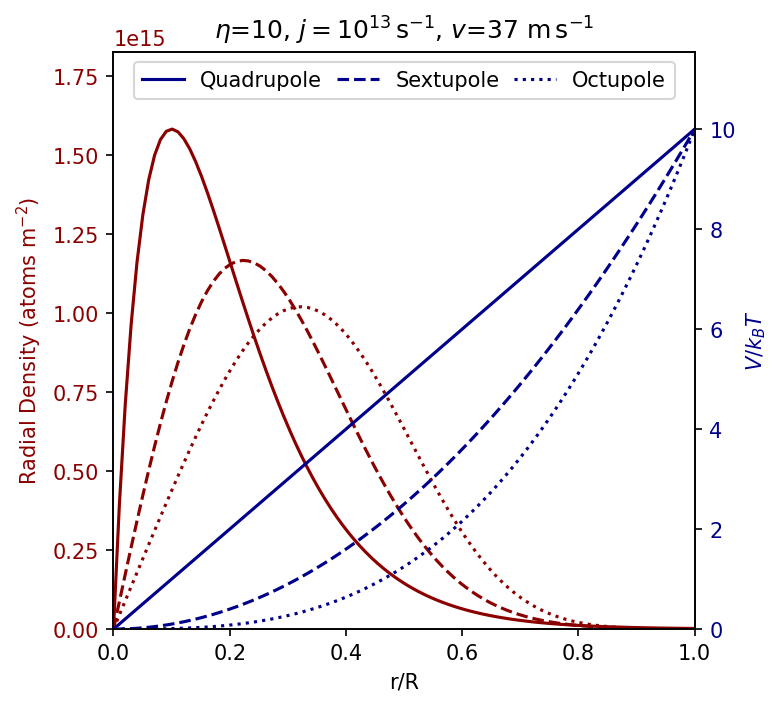

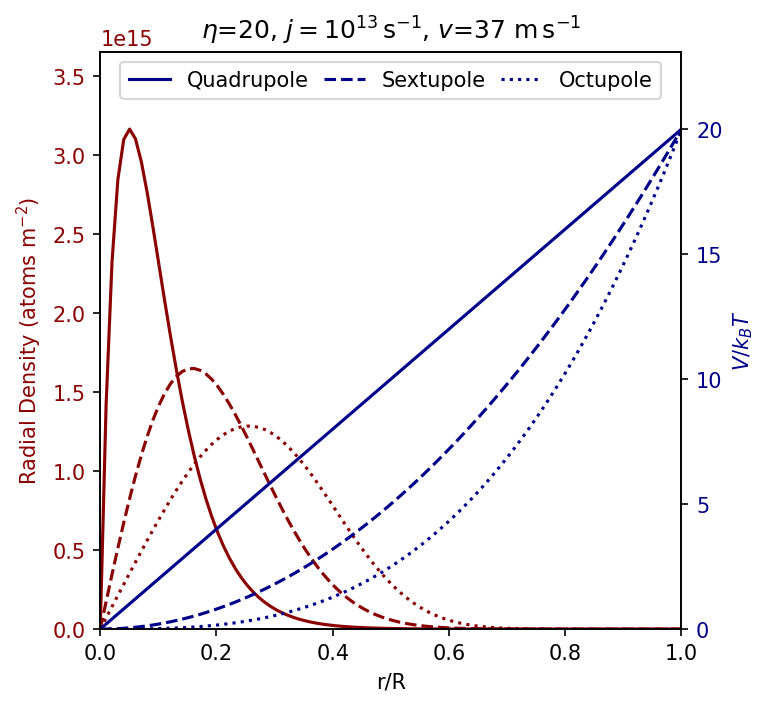

In [18]:
for eta in (5,10,20):

    rps=np.linspace(0,1,100)
    fig, ax1 = plt.subplots(figsize=(5,5),dpi=150) 
    Ns=[4,6,8]
    LineTypes=['-','--',':']
    Names=['Quadrupole','Sextupole','Octupole']
    ax1.set_xlabel('r/R')
    ax2 = ax1.twinx() 
    ax2.tick_params(axis ='y', labelcolor = 'DarkBlue') 
    ax2.set_ylabel('$V / k_B T$',color='DarkBlue') 


    ax1.tick_params(axis ='y', labelcolor = 'DarkRed') 
    ax1.set_ylabel('Radial Density (atoms m$^{-2}$)',color='DarkRed') 

    for Ni in range(0,len(Ns)):
        ax2.plot(rps,Potential(rps,eta,Ns[Ni]),color='DarkBlue',label=Names[Ni],linestyle=LineTypes[Ni]) 
        ax1.plot(rps,DensityFixedR(rps,eta,Ns[Ni],j0,v0,R0)*rps,color='DarkRed',linestyle=LineTypes[Ni]) 
    plt.xlim(0,1)
    ax1.set_ylim(0,ax1.get_ylim()[1]*1.1)
    ax2.set_ylim(0,ax2.get_ylim()[1]*1.1)

    ax2.legend(loc='upper center',ncol=3,columnspacing=0.7)
    plt.title("$\eta$="+str(eta)+", $j=10^{13}\, \mathrm{s}^{-1}$, $v$="+str(v0)+" $\mathrm{m\,s}^{-1}$")

    plt.show()
    


In [19]:
def EKin(rp,eta,N,j,v,R):
    return 3/2*DensityFixedR(rp,eta,N,j,v,R)
def EPot(rp,eta,N,j,v,R):
    return DensityFixedR(rp,eta,N,j,v,R)*Potential(rp,eta,N)

<>:25: SyntaxWarning: invalid escape sequence '\e'
<>:25: SyntaxWarning: invalid escape sequence '\,'
<>:25: SyntaxWarning: invalid escape sequence '\m'
<>:25: SyntaxWarning: invalid escape sequence '\e'
<>:25: SyntaxWarning: invalid escape sequence '\,'
<>:25: SyntaxWarning: invalid escape sequence '\m'
/var/folders/x8/m88g9m690wb3gf4t7ds85nzw0000gn/T/ipykernel_22009/441732300.py:25: SyntaxWarning: invalid escape sequence '\e'
  plt.title("$\eta$="+str(eta)+", $j=10^{13}\, \mathrm{s}^{-1}$, $v$="+str(v0)+" $\mathrm{m\,s}^{-1}$")
/var/folders/x8/m88g9m690wb3gf4t7ds85nzw0000gn/T/ipykernel_22009/441732300.py:25: SyntaxWarning: invalid escape sequence '\,'
  plt.title("$\eta$="+str(eta)+", $j=10^{13}\, \mathrm{s}^{-1}$, $v$="+str(v0)+" $\mathrm{m\,s}^{-1}$")
/var/folders/x8/m88g9m690wb3gf4t7ds85nzw0000gn/T/ipykernel_22009/441732300.py:25: SyntaxWarning: invalid escape sequence '\m'
  plt.title("$\eta$="+str(eta)+", $j=10^{13}\, \mathrm{s}^{-1}$, $v$="+str(v0)+" $\mathrm{m\,s}^{-1}$")


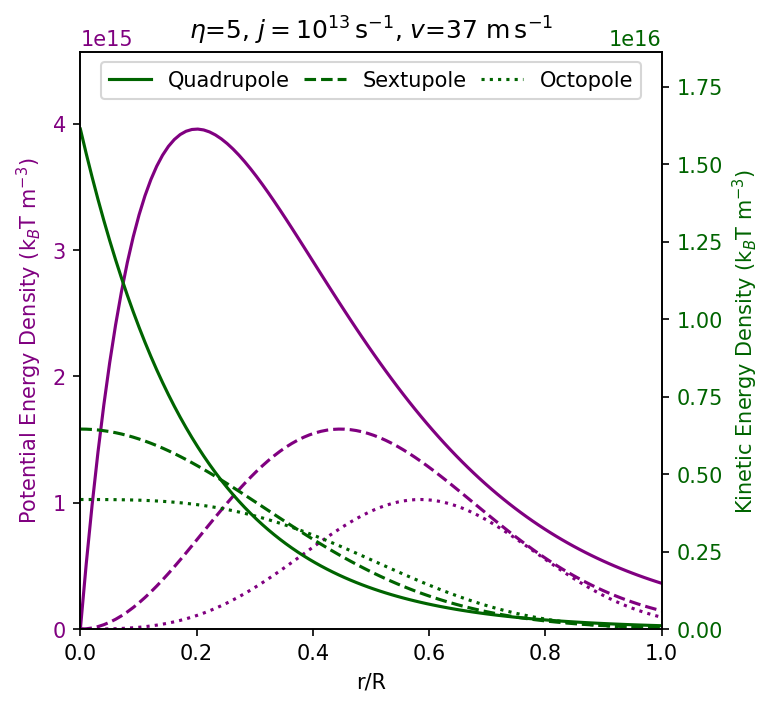

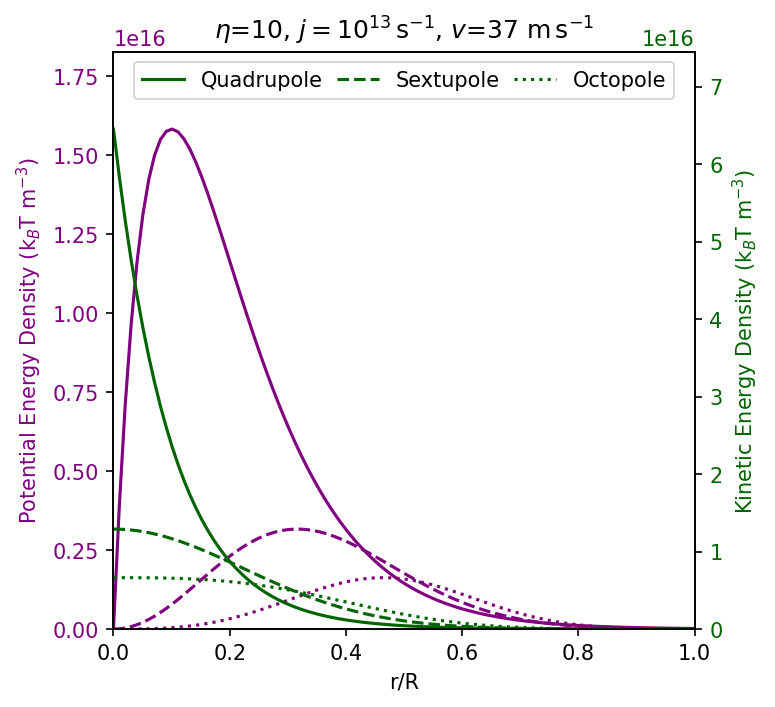

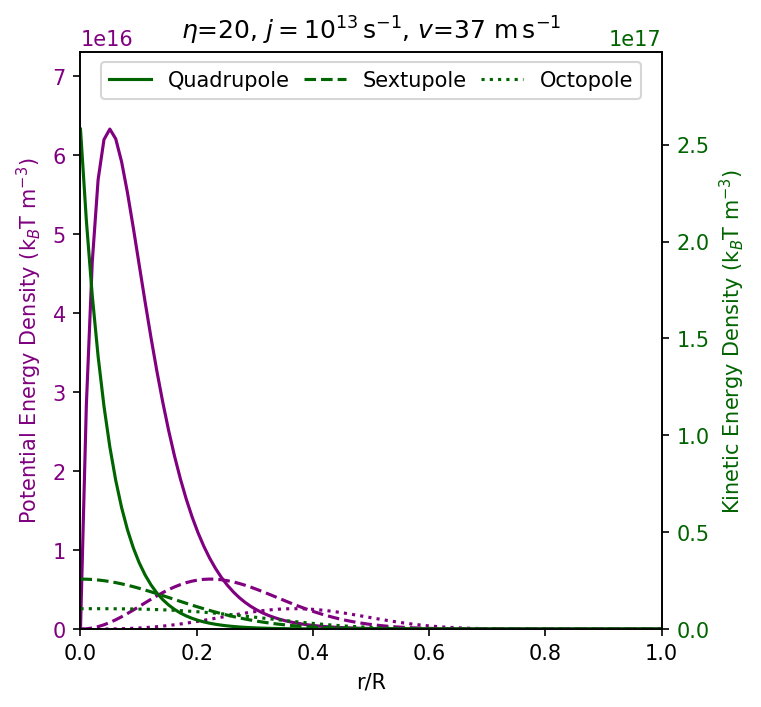

In [20]:
for eta in (5,10,20):

    rps=np.linspace(0,1,100)
    fig, ax1 = plt.subplots(figsize=(5,5),dpi=150) 
    Ns=[4,6,8]
    LineTypes=['-','--',':']
    Names=['Quadrupole','Sextupole','Octopole']
    ax1.set_xlabel('r/R')
    ax2 = ax1.twinx() 
    ax2.tick_params(axis ='y', labelcolor = 'DarkGreen') 
    ax2.set_ylabel('Kinetic Energy Density (k$_B$T m$^{-3}$)',color='DarkGreen') 


    ax1.tick_params(axis ='y', labelcolor = 'purple') 
    ax1.set_ylabel('Potential Energy Density (k$_B$T m$^{-3}$)',color='purple') 

    for Ni in range(0,len(Ns)):
        ax2.plot(rps,EKin(rps,eta,Ns[Ni],j0,v0,R0),color='DarkGreen',label=Names[Ni],linestyle=LineTypes[Ni]) 
        ax1.plot(rps,EPot(rps,eta,Ns[Ni],j0,v0,R0),color='purple',linestyle=LineTypes[Ni]) 
    plt.xlim(0,1)
    ax1.set_ylim(0,ax1.get_ylim()[1]*1.1)
    ax2.set_ylim(0,ax2.get_ylim()[1]*1.1)

    ax2.legend(loc='upper center',ncol=3,columnspacing=0.7)
    plt.title("$\eta$="+str(eta)+", $j=10^{13}\, \mathrm{s}^{-1}$, $v$="+str(v0)+" $\mathrm{m\,s}^{-1}$")


    plt.show()
    

<>:25: SyntaxWarning: invalid escape sequence '\,'
<>:25: SyntaxWarning: invalid escape sequence '\m'
<>:25: SyntaxWarning: invalid escape sequence '\,'
<>:25: SyntaxWarning: invalid escape sequence '\m'
/var/folders/x8/m88g9m690wb3gf4t7ds85nzw0000gn/T/ipykernel_22009/2110161760.py:25: SyntaxWarning: invalid escape sequence '\,'
  plt.title(r"$\eta$="+str(eta)+", $j=10^{13}\, \mathrm{s}^{-1}$, $v$="+str(v0)+" $\mathrm{m\,s}^{-1}$")
/var/folders/x8/m88g9m690wb3gf4t7ds85nzw0000gn/T/ipykernel_22009/2110161760.py:25: SyntaxWarning: invalid escape sequence '\m'
  plt.title(r"$\eta$="+str(eta)+", $j=10^{13}\, \mathrm{s}^{-1}$, $v$="+str(v0)+" $\mathrm{m\,s}^{-1}$")


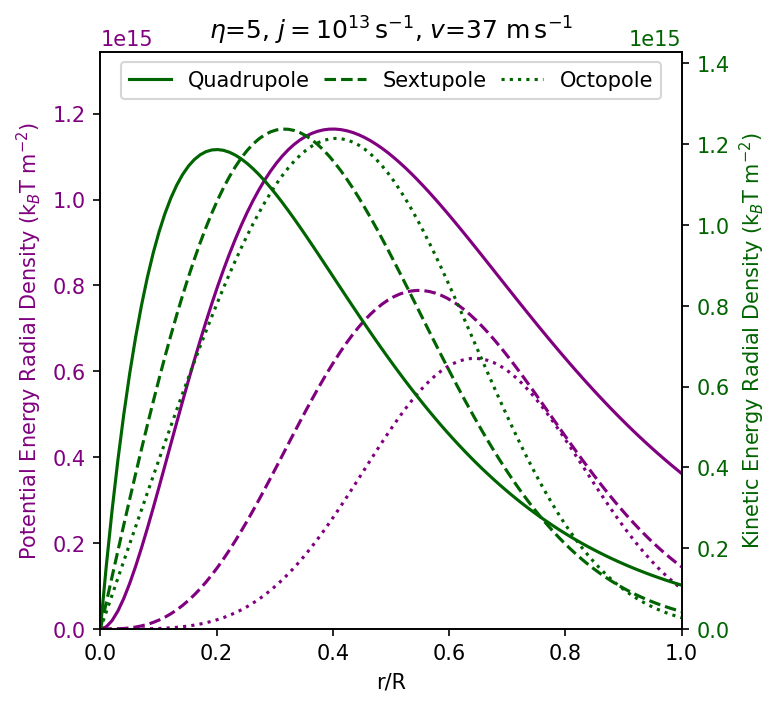

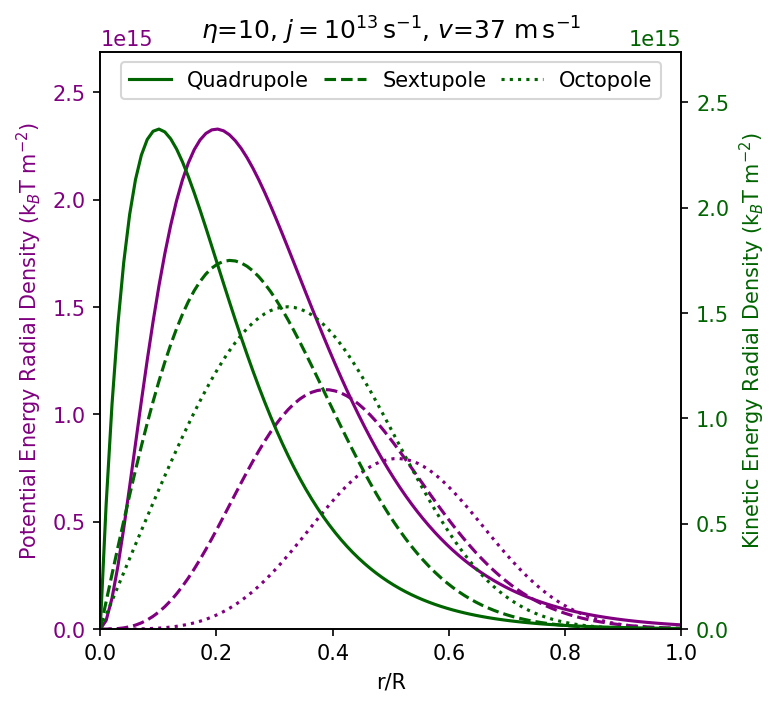

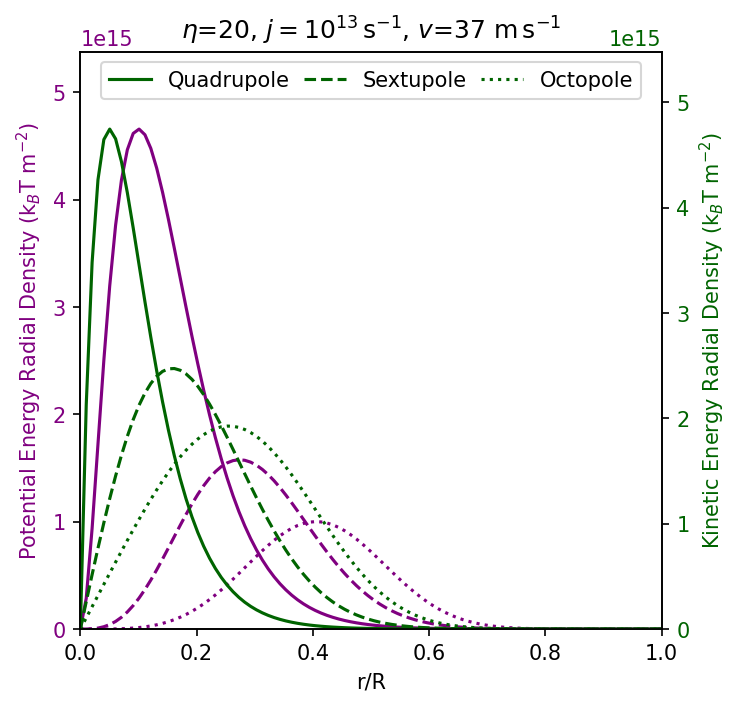

In [21]:
for eta in (5,10,20):

    rps=np.linspace(0,1,100)
    fig, ax1 = plt.subplots(figsize=(5,5),dpi=150) 
    Ns=[4,6,8]
    LineTypes=['-','--',':']
    Names=['Quadrupole','Sextupole','Octopole']
    ax1.set_xlabel('r/R')
    ax2 = ax1.twinx() 
    ax2.tick_params(axis ='y', labelcolor = 'DarkGreen') 
    ax2.set_ylabel('Kinetic Energy Radial Density (k$_B$T m$^{-2}$)',color='DarkGreen') 


    ax1.tick_params(axis ='y', labelcolor = 'purple') 
    ax1.set_ylabel('Potential Energy Radial Density (k$_B$T m$^{-2}$)',color='purple') 

    for Ni in range(0,len(Ns)):
        ax2.plot(rps,EKin(rps,eta,Ns[Ni],j0,v0,R0)*rps,color='DarkGreen',label=Names[Ni],linestyle=LineTypes[Ni]) 
        ax1.plot(rps,EPot(rps,eta,Ns[Ni],j0,v0,R0)*rps,color='purple',linestyle=LineTypes[Ni]) 
    plt.xlim(0,1)
    ax1.set_ylim(0,ax1.get_ylim()[1]*1.1)
    ax2.set_ylim(0,ax2.get_ylim()[1]*1.1)

    ax2.legend(loc='upper center',ncol=3,columnspacing=0.7)
    plt.title(r"$\eta$="+str(eta)+", $j=10^{13}\, \mathrm{s}^{-1}$, $v$="+str(v0)+" $\mathrm{m\,s}^{-1}$")

    plt.show()

In [22]:
def etacut(rp,eta,N):
    return((1-(rp)**(N/2-1))*eta)


<>:7: SyntaxWarning: invalid escape sequence '\e'
<>:7: SyntaxWarning: invalid escape sequence '\e'
/var/folders/x8/m88g9m690wb3gf4t7ds85nzw0000gn/T/ipykernel_22009/2966930467.py:7: SyntaxWarning: invalid escape sequence '\e'
  plt.ylabel("ejection cut, $\eta_{cut}$")


Text(0.5, 1.0, '$\\eta$=20')

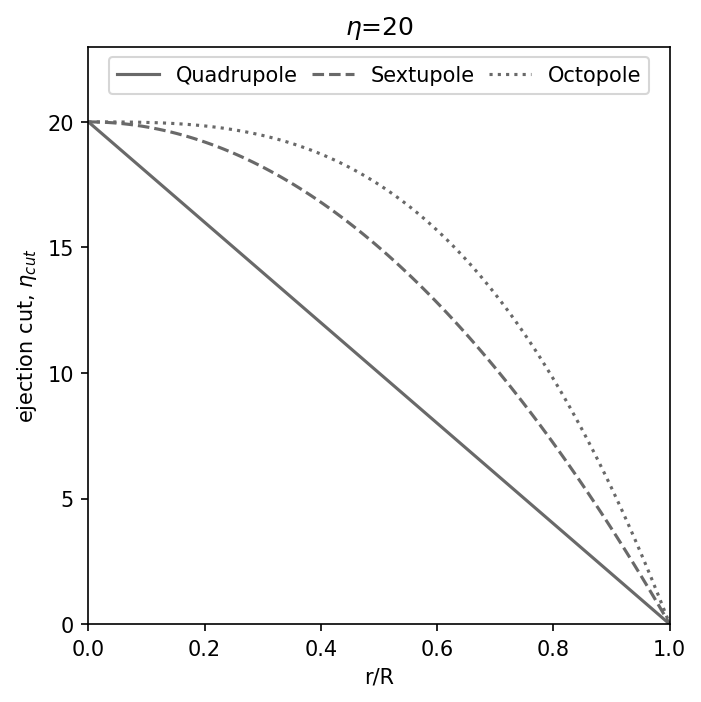

In [23]:
plt.figure(figsize=(5,5),dpi=150)
rps=np.linspace(0,1,100)

for Ni in range(0,len(Ns)):
    plt.plot(rps,etacut(rps,eta,Ns[Ni]),linestyle=LineTypes[Ni],color='dimgrey',label=Names[Ni])
plt.xlabel("r/R")
plt.ylabel("ejection cut, $\eta_{cut}$")
plt.xlim(0,1)
plt.ylim(0,23)
plt.legend(loc='upper center',ncol=3,columnspacing=0.7)

plt.title(r"$\eta$=20")

In [24]:
f=open("./GammaFile_T1K_rho1e18.pkl",'rb')
LogGammaE,LogGammaN=pickle.load(f)
f.close()
GammaN=lambda eta: np.exp(LogGammaN(eta))
GammaE=lambda eta: np.exp(LogGammaE(eta))

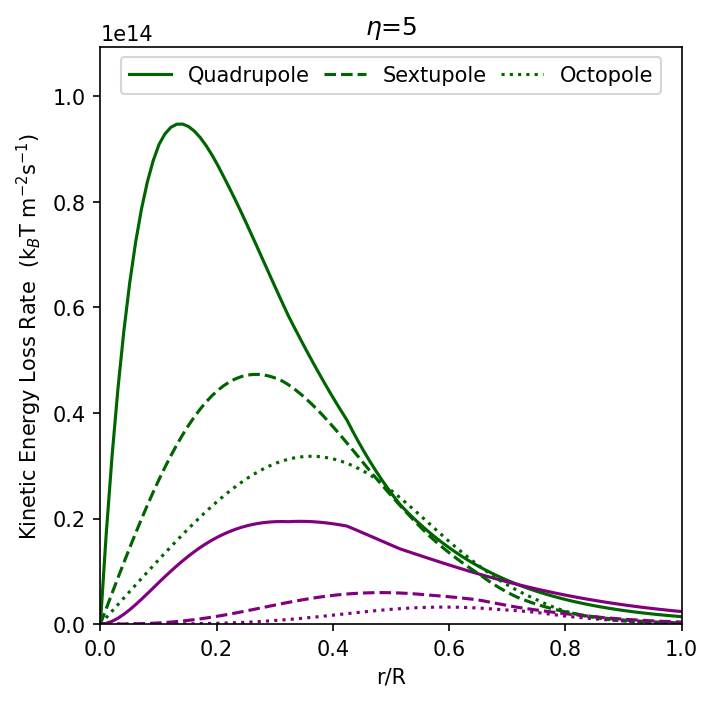

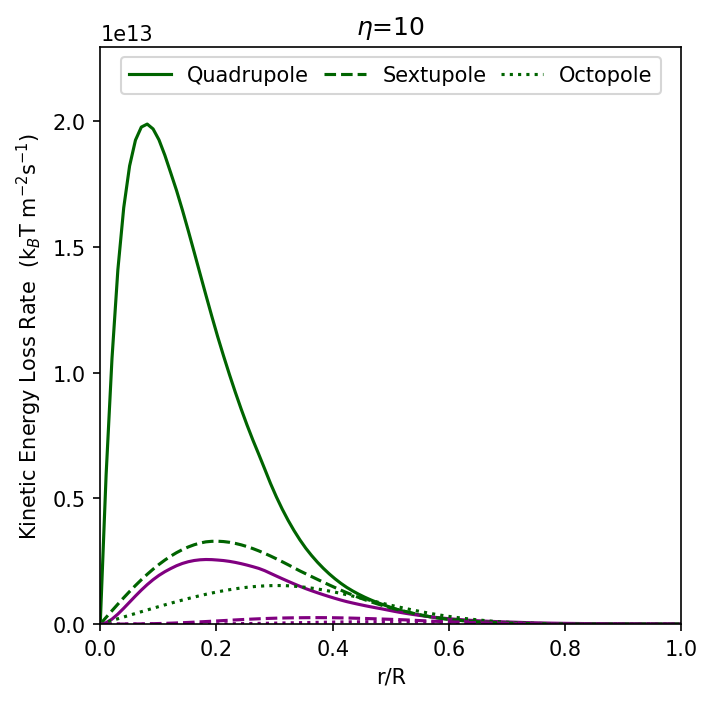

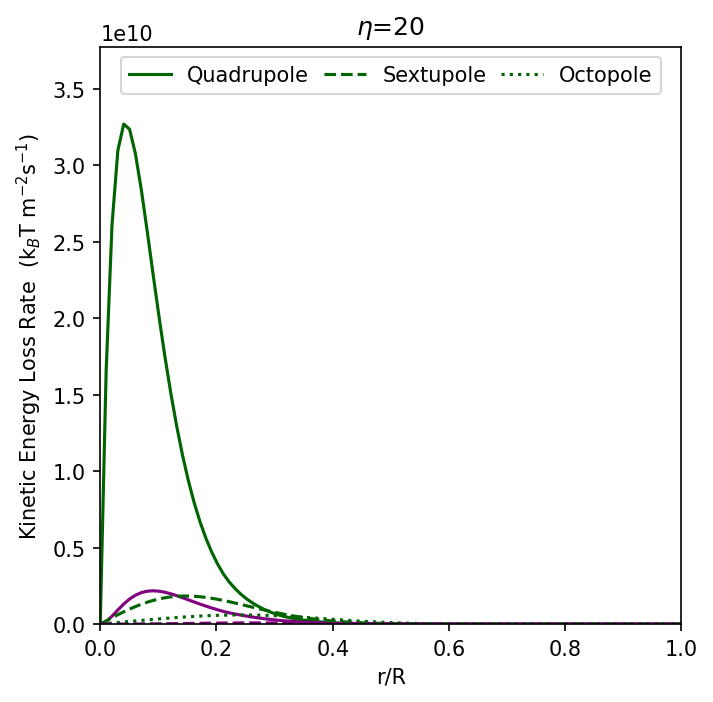

In [25]:
rps=np.linspace(0,1,100)
for eta in (5,10,20):
    plt.figure(figsize=(5,5),dpi=150)

    for Ni in range(0,len(Ns)):
        plt.plot(rps, EKin(rps,eta,Ns[Ni],j0,v0,R0)*GammaE(etacut(rps,eta,Ns[Ni]))*(DensityFixedR(rps,eta,Ns[Ni],j0,v0,R0)/rho0)* (2.*np.pi*rps),linestyle=LineTypes[Ni],color='DarkGreen',label=Names[Ni])
        plt.plot(rps, EPot(rps,eta,Ns[Ni],j0,v0,R0)*GammaN(etacut(rps,eta,Ns[Ni]))*(DensityFixedR(rps,eta,Ns[Ni],j0,v0,R0)/rho0)* (2.*np.pi*rps),linestyle=LineTypes[Ni],color='purple')

    plt.xlabel("r/R")
    plt.ylabel("Kinetic Energy Loss Rate  (k$_B$T m$^{-2}$s$^{-1}$)")
    plt.xlim(0,1)
    #plt.ylim(0,23)
    plt.legend(loc='upper center',ncol=3,columnspacing=0.7)
    plt.ylim(0,plt.ylim()[1]*1.1)

    plt.title(r"$\eta$="+str(eta))
    plt.show()

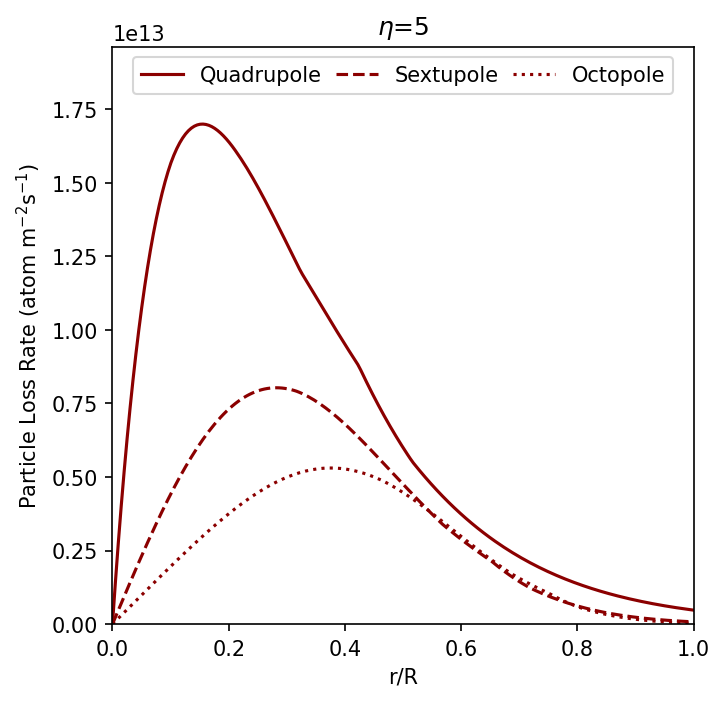

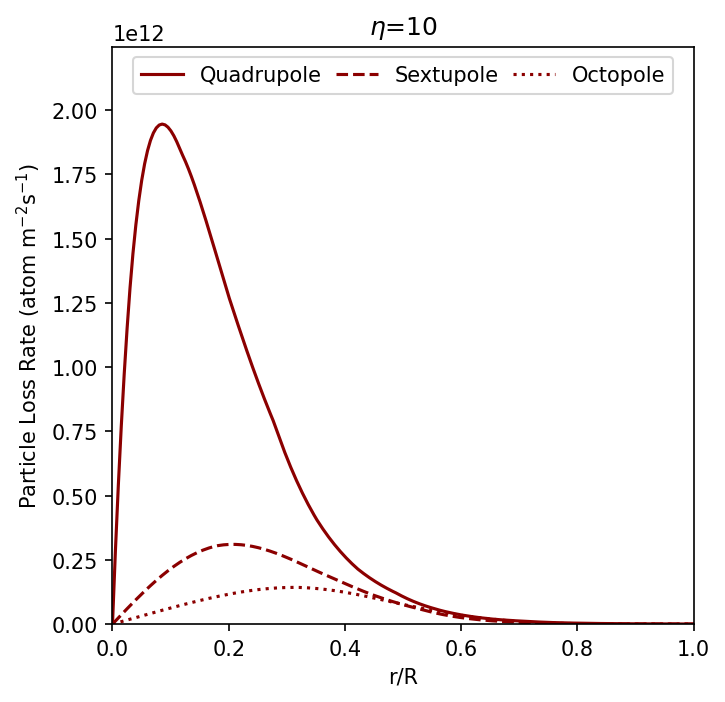

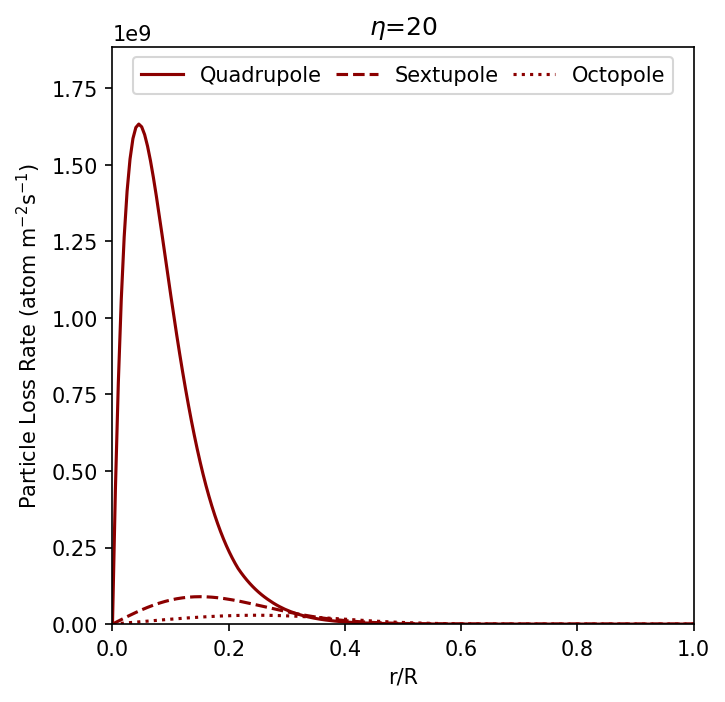

In [26]:
rps=np.linspace(0,1,200)
for eta in (5,10,20):
    plt.figure(figsize=(5,5),dpi=150)

    for Ni in range(0,len(Ns)):
        plt.plot(rps, GammaN(etacut(rps,eta,Ns[Ni]))*(DensityFixedR(rps,eta,Ns[Ni],j0,v0,R0)/rho0)*DensityFixedR(rps,eta,Ns[Ni],j0,v0,R0)*(2*np.pi*rps),linestyle=LineTypes[Ni],color='DarkRed',label=Names[Ni])
    plt.xlabel("r/R")
    plt.ylabel("Particle Loss Rate (atom m$^{-2}$s$^{-1}$)")
    plt.xlim(0,1)
    #plt.ylim(0,23)
    plt.legend(loc='upper center',ncol=3,columnspacing=0.7)
    plt.ylim(0,plt.ylim()[1]*1.1)

    plt.title(r"$\eta$="+str(eta))
    plt.show()

In [27]:
def TotalLosses(eta,N,j,v,R,bins=1000):
    rps=np.linspace(0,1,bins)
    particlelosses=sum(GammaN(etacut(rps,eta,N))*(DensityFixedR(rps,eta,N,j,v,R)/rho0)*DensityFixedR(rps,eta,N,j,v,R)*(2*np.pi*rps)*R**2/bins)
    kinlosses=sum(EKin(rps,eta,N,j,v,R)*GammaE(etacut(rps,eta,N))*(DensityFixedR(rps,eta,N,j,v,R)/rho0)* (2.*np.pi*rps)*R**2/bins)
    potlosses=sum(EPot(rps,eta,N,j,v,R)*GammaN(etacut(rps,eta,N))*(DensityFixedR(rps,eta,N,j,v,R)/rho0)* (2.*np.pi*rps)*R**2/bins)
    energylosses=kinlosses+potlosses
    return(np.array([particlelosses,kinlosses,potlosses,energylosses]))

def TotalCounts(eta,N,j,v,R,bins=1000):
    rps=np.linspace(0,1,bins)
    particles=sum(DensityFixedR(rps,eta,N,j,v,R)*(2*np.pi*rps)*R**2/bins)
    kin=sum(EKin(rps,eta,N,j,v,R)* (2.*np.pi*rps)*R**2/bins)
    pot=sum(EPot(rps,eta,N,j,v,R)* (2.*np.pi*rps)*R**2/bins)
    energy=kin+pot
    return(np.array([particles,kin,pot,energy]))

def FracLosses(eta,N,j,v,R,bins=1000):
    return(TotalLosses(eta,N,j,v,R,bins)/TotalCounts(eta,N,j,v,R,bins))

In [28]:
TotalLosses(eta,4,j0,v0,R0)

array([ 20192.63232975, 386103.05613541,  37027.49977169, 423130.55590711])

In [29]:
TotalCounts(eta,4,j0,v0,R0)

array([2.69990971e+11, 4.04986456e+11, 5.39999756e+11, 9.44986212e+11])

In [30]:
FracLosses(20,4,j0,v0,R0)

array([7.47900283e-08, 9.53372762e-07, 6.85694750e-08, 4.47763735e-07])

Text(0.5, 1.0, '$j$=10000000000000.0 s$^{-1}$, $v$=37 ms$^{-1}$, R=5cm')

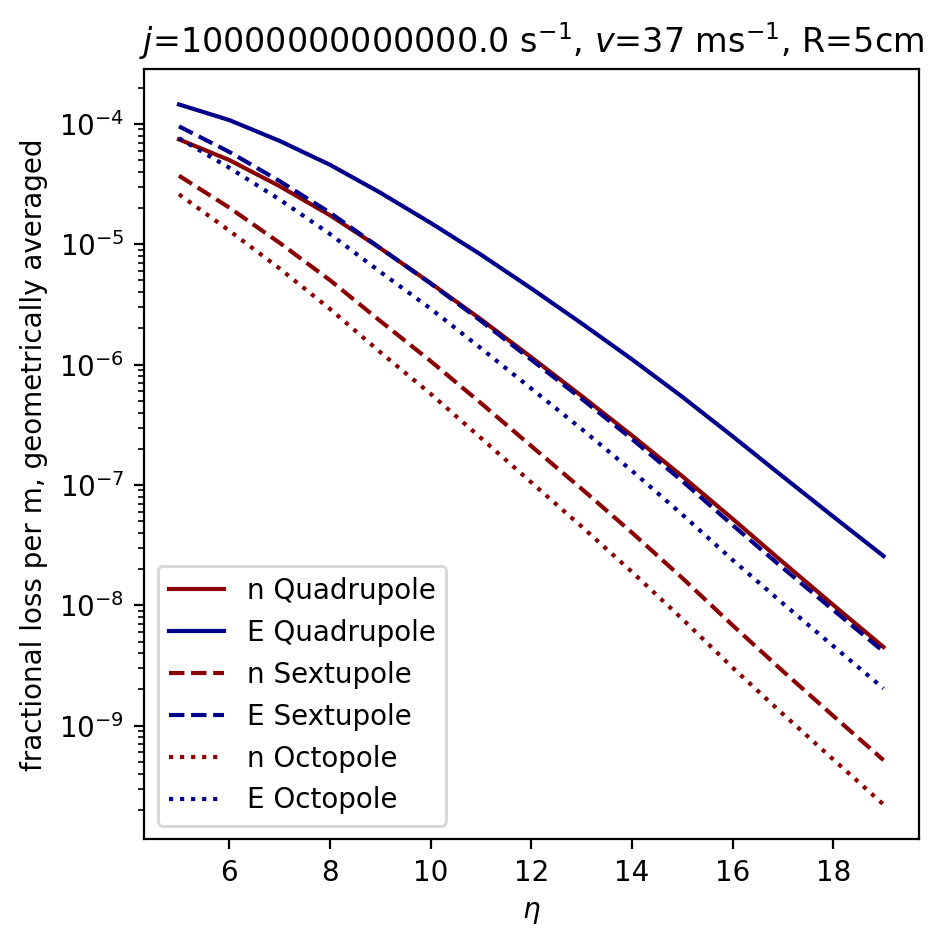

In [31]:
plt.figure(figsize=(5,5),dpi=200)

for Ni in range(0,len(Ns)):
    N=Ns[Ni]
    etas=range(5,20)
    AllFracLosses=[]

    for eta in etas:

        AllFracLosses.append(FracLosses(eta,N,j0,v0,R0))
    AllFracLossesPerM=np.array(AllFracLosses)/v0
    plt.plot(etas,AllFracLossesPerM[:,0],label='n '+str(Names[Ni]),color='DarkRed',linestyle=LineTypes[Ni])
    #plt.plot(etas,AllFracLossesPerM[:,1],'--',label='kinetic E',color='DarkGreen')x
    #plt.plot(etas,AllFracLossesPerM[:,2],'--',label='potential E',color='purple')
    plt.plot(etas,AllFracLossesPerM[:,3],label='E '+str(Names[Ni]),color='DarkBlue',linestyle=LineTypes[Ni])

    plt.semilogy()
    plt.xlabel(r"$\eta$")
    plt.ylabel("fractional loss per m, geometrically averaged")
plt.legend(loc='lower left')
plt.title("$j$="+str(j0)+" s$^{-1}$, $v$="+str(v0)+" ms$^{-1}$, R=5cm")



Text(0.5, 1.0, '$j$=10000000000000.0 s$^{-1}$, $v$=37 ms$^{-1}$, R=2.5cm')

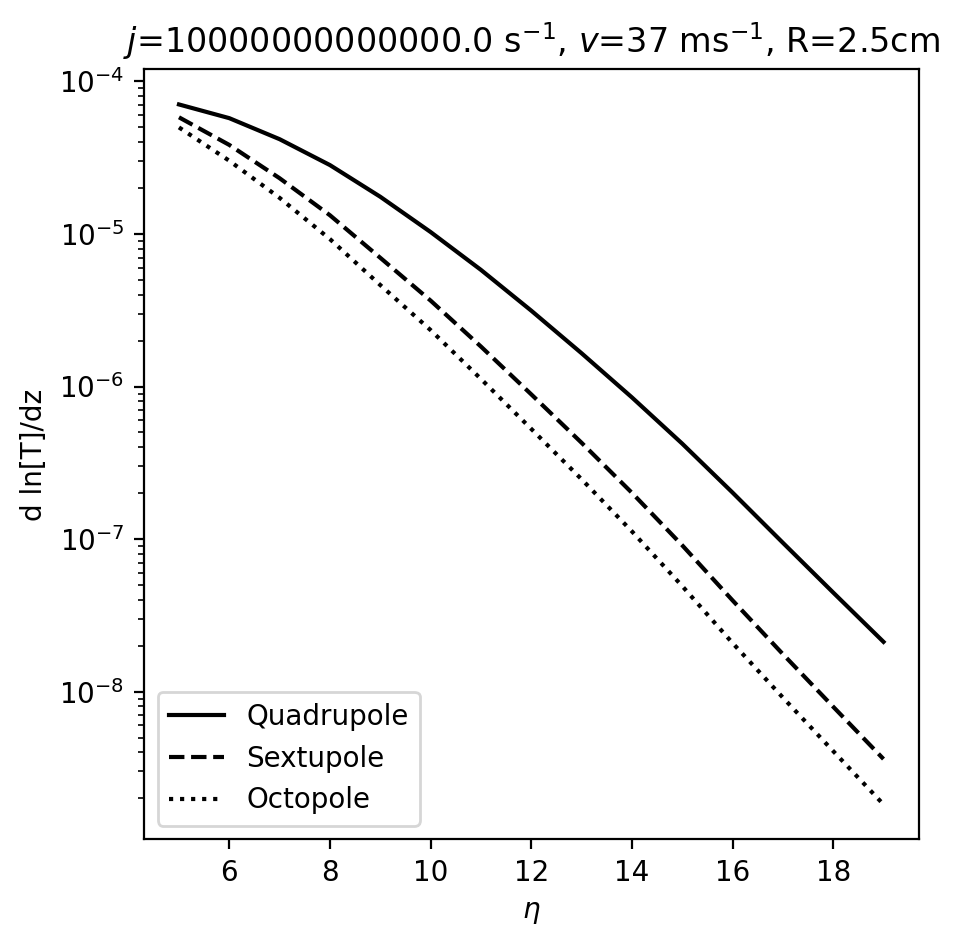

In [32]:
plt.figure(figsize=(5,5),dpi=200)

for Ni in range(0,len(Ns)):
    N=Ns[Ni]
    etas=range(5,20)
    AllFracLosses=[]

    for eta in etas:

        AllFracLosses.append(FracLosses(eta,N,j0,v0,R0))
    AllFracLossesPerM=np.array(AllFracLosses)/v0
    #plt.plot(etas,AllFracLossesPerM[:,1],'--',label='kinetic E',color='DarkGreen')x
    #plt.plot(etas,AllFracLossesPerM[:,2],'--',label='potential E',color='purple')
    plt.plot(etas,AllFracLossesPerM[:,3]-AllFracLossesPerM[:,0],color='black',linestyle=LineTypes[Ni],label=Names[Ni])

plt.semilogy()
plt.xlabel(r"$\eta$")
plt.ylabel("d ln[T]/dz")
plt.legend(loc='lower left')
plt.title("$j$="+str(j0)+" s$^{-1}$, $v$="+str(v0)+" ms$^{-1}$, R=2.5cm")


Text(0.5, 1.0, '$j$=10000000000000.0 s$^{-1}$, $v$=37 ms$^{-1}$, eta=10')

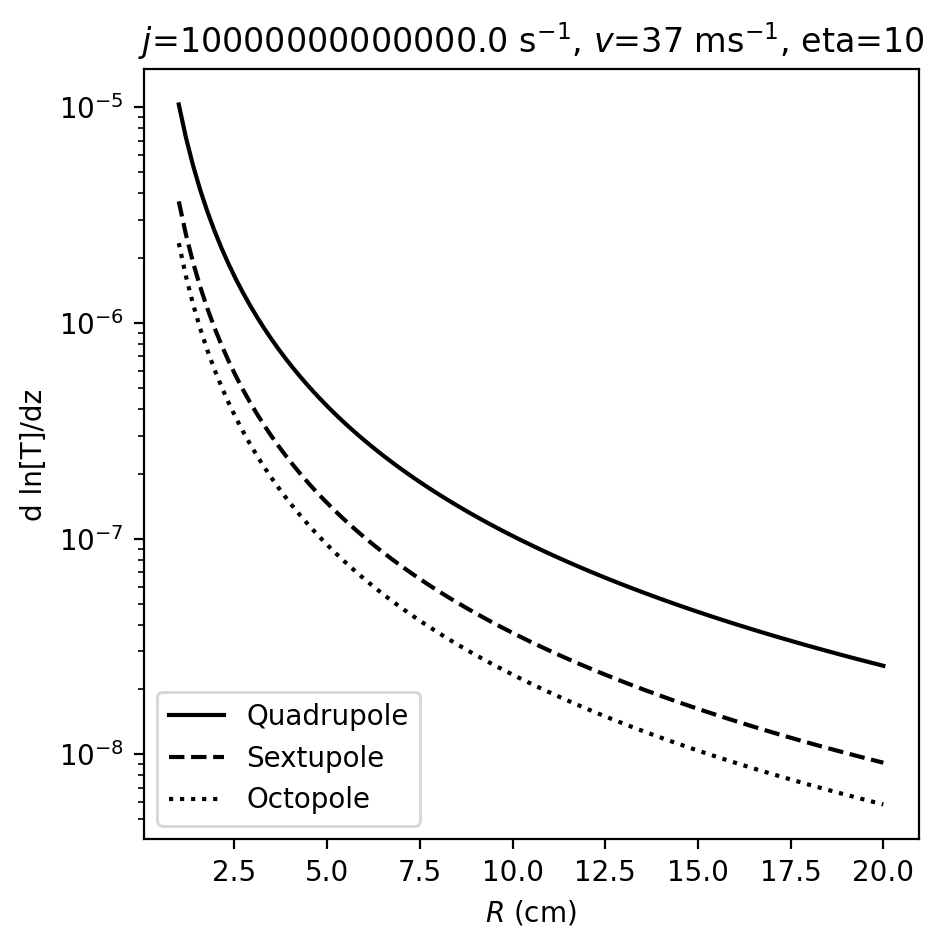

In [33]:
plt.figure(figsize=(5,5),dpi=200)

for Ni in range(0,len(Ns)):
    N=Ns[Ni]
    Rs=np.linspace(0.01,0.2,100)
    AllFracLosses=[]

    for R in Rs:

        AllFracLosses.append(FracLosses(10,N,j0,v0,R))
    AllFracLossesPerM=np.array(AllFracLosses)/v0
    #plt.plot(etas,AllFracLossesPerM[:,1],'--',label='kinetic E',color='DarkGreen')x
    #plt.plot(etas,AllFracLossesPerM[:,2],'--',label='potential E',color='purple')
    plt.plot(Rs*100,AllFracLossesPerM[:,3]-AllFracLossesPerM[:,0],color='black',linestyle=LineTypes[Ni],label=Names[Ni])

plt.semilogy()
plt.xlabel(r"$R$ (cm)")
plt.ylabel("d ln[T]/dz")
plt.legend(loc='lower left')
plt.title("$j$="+str(j0)+" s$^{-1}$, $v$="+str(v0)+" ms$^{-1}$, eta=10")

Text(0.5, 1.0, '$R$=2.5cm, $v$=37 ms$^{-1}$, eta=10')

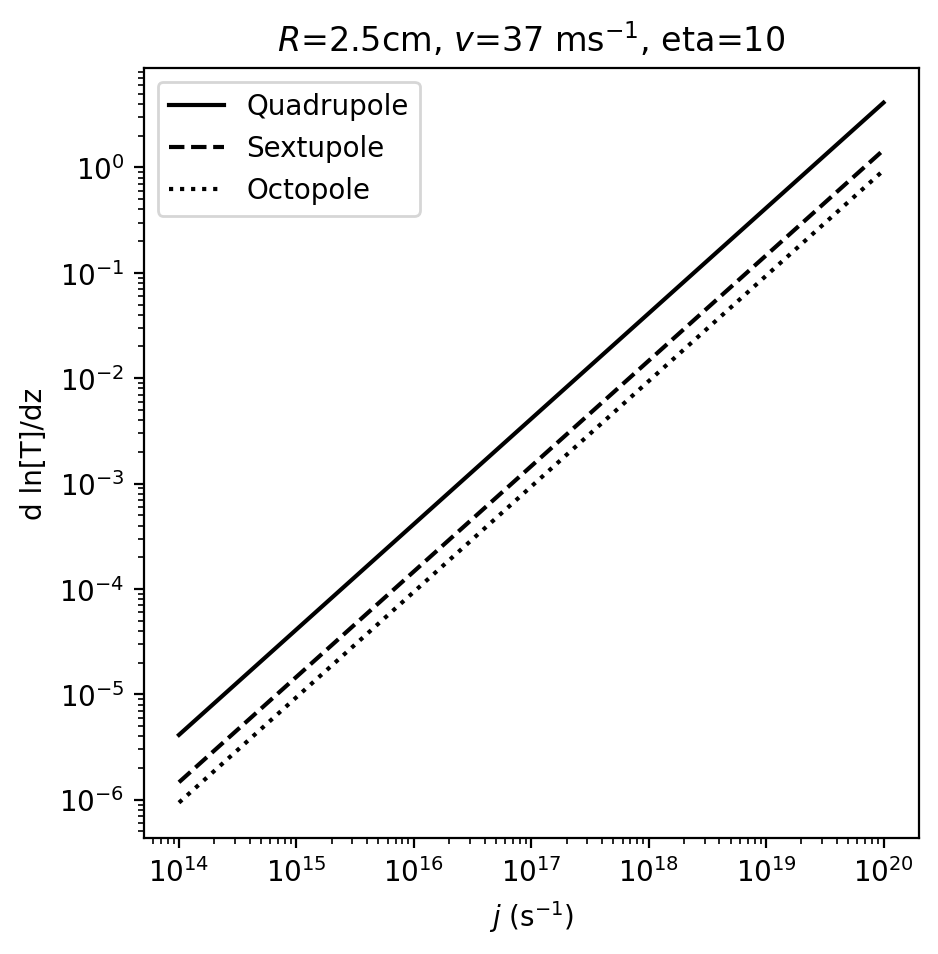

In [34]:
plt.figure(figsize=(5,5),dpi=200)

for Ni in range(0,len(Ns)):
    N=Ns[Ni]
    js=np.logspace(14,20,100)
    AllFracLosses=[]

    for j in js:

        AllFracLosses.append(FracLosses(10,N,j,v0,0.05))
    AllFracLossesPerM=np.array(AllFracLosses)/v0
    #plt.plot(etas,AllFracLossesPerM[:,1],'--',label='kinetic E',color='DarkGreen')x
    #plt.plot(etas,AllFracLossesPerM[:,2],'--',label='potential E',color='purple')
    plt.plot(js,AllFracLossesPerM[:,3]-AllFracLossesPerM[:,0],color='black',linestyle=LineTypes[Ni],label=Names[Ni])

plt.loglog()
plt.xlabel(r"$j$ (s$^{-1}$)")
plt.ylabel("d ln[T]/dz")
plt.legend(loc='upper left')
plt.title("$R$=2.5cm, $v$="+str(v0)+" ms$^{-1}$, eta=10")